In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

In [2]:
df = pd.read_csv("CleanedBurnoutData.csv")
#df .info

<Figure size 1000x600 with 0 Axes>

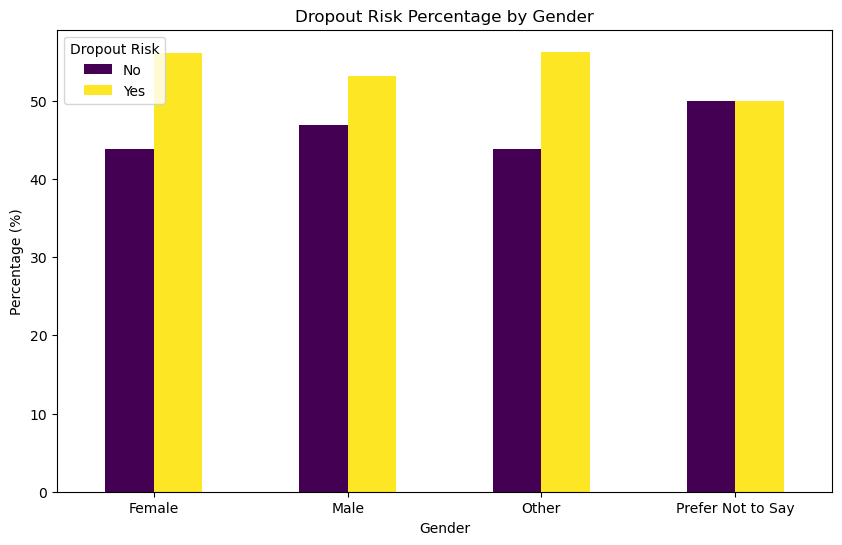

In [3]:
# Create the percentage table again (if needed)
table = pd.crosstab(df['Gender'], df['Dropout_Risk'], normalize='index') * 100

plt.figure(figsize=(10,6))
table.plot(kind='bar', figsize=(10,6), colormap='viridis')

plt.title('Dropout Risk Percentage by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.legend(title='Dropout Risk')
plt.xticks(rotation=0)
plt.show()

In [4]:
df_yes = df[df['Dropout_Risk'] == 'Yes']
unique_counts = df_yes.nunique()
df_yes = df_yes.drop(columns=['Student_ID', 'Gender', 'Dropout_Risk'])

# Select categorical columns (object type)
cat_cols = df_yes.select_dtypes(include='object').columns.tolist()

# Melt into long format: Column / Value
df_melt = df_yes[cat_cols].melt(var_name='Column', value_name='Value')

# Count how many times each value appears in each column
counts = df_melt.value_counts(['Column', 'Value']).reset_index(name='Count')

# Pivot so each column is a bar, and each unique value is a stacked segment
pivot = counts.pivot(index='Column', columns='Value', values='Count').fillna(0)

<Figure size 1800x600 with 0 Axes>

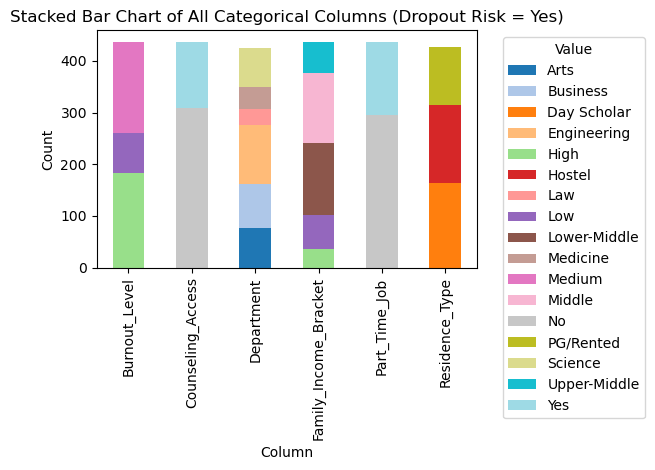

In [5]:
plt.figure(figsize=(18,6))
ax = pivot.plot(kind='bar', stacked=True, colormap='tab20')

plt.title('Stacked Bar Chart of All Categorical Columns (Dropout Risk = Yes)')
plt.xlabel('Column')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.legend(title='Value', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- Add labels to each stacked segment ---
for container in ax.containers:
    ax.bar_label(container, label_type='center', fontsize=8)

plt.show()

In [6]:
def percent_table(df, column):
    return (df[column].value_counts(normalize=True) * 100).round(2)

burnout_pct = percent_table(df_yes, 'Burnout_Level')
counsel_pct = percent_table(df_yes, 'Counseling_Access')
dept_pct = percent_table(df_yes, 'Department')
parttime_pct = percent_table(df_yes, 'Part_Time_Job')
residence_pct = percent_table(df_yes, 'Residence_Type')
familyincome_pct = percent_table(df_yes, 'Family_Income_Bracket')

print("Burnout Level (%)\n", burnout_pct, "\n")
print("Counseling Access (%)\n", counsel_pct, "\n")
print("Department (%)\n", dept_pct, "\n")
print("Part-Time Job (%)\n", parttime_pct, "\n")
print("Residence Type (%)\n", residence_pct, "\n")
print("Family Income (%)\n", familyincome_pct, "\n")

Burnout Level (%)
 Burnout_Level
High      42.11
Medium    40.50
Low       17.39
Name: proportion, dtype: float64 

Counseling Access (%)
 Counseling_Access
No     70.48
Yes    29.52
Name: proportion, dtype: float64 

Department (%)
 Department
Engineering    26.59
Business       20.00
Arts           18.12
Science        17.88
Medicine        9.88
Law             7.53
Name: proportion, dtype: float64 

Part-Time Job (%)
 Part_Time_Job
No     67.51
Yes    32.49
Name: proportion, dtype: float64 

Residence Type (%)
 Residence_Type
Day Scholar    38.17
Hostel         35.60
PG/Rented      26.23
Name: proportion, dtype: float64 

Family Income (%)
 Family_Income_Bracket
Lower-Middle    32.04
Middle          30.89
Low             14.87
Upper-Middle    13.96
High             8.24
Name: proportion, dtype: float64 



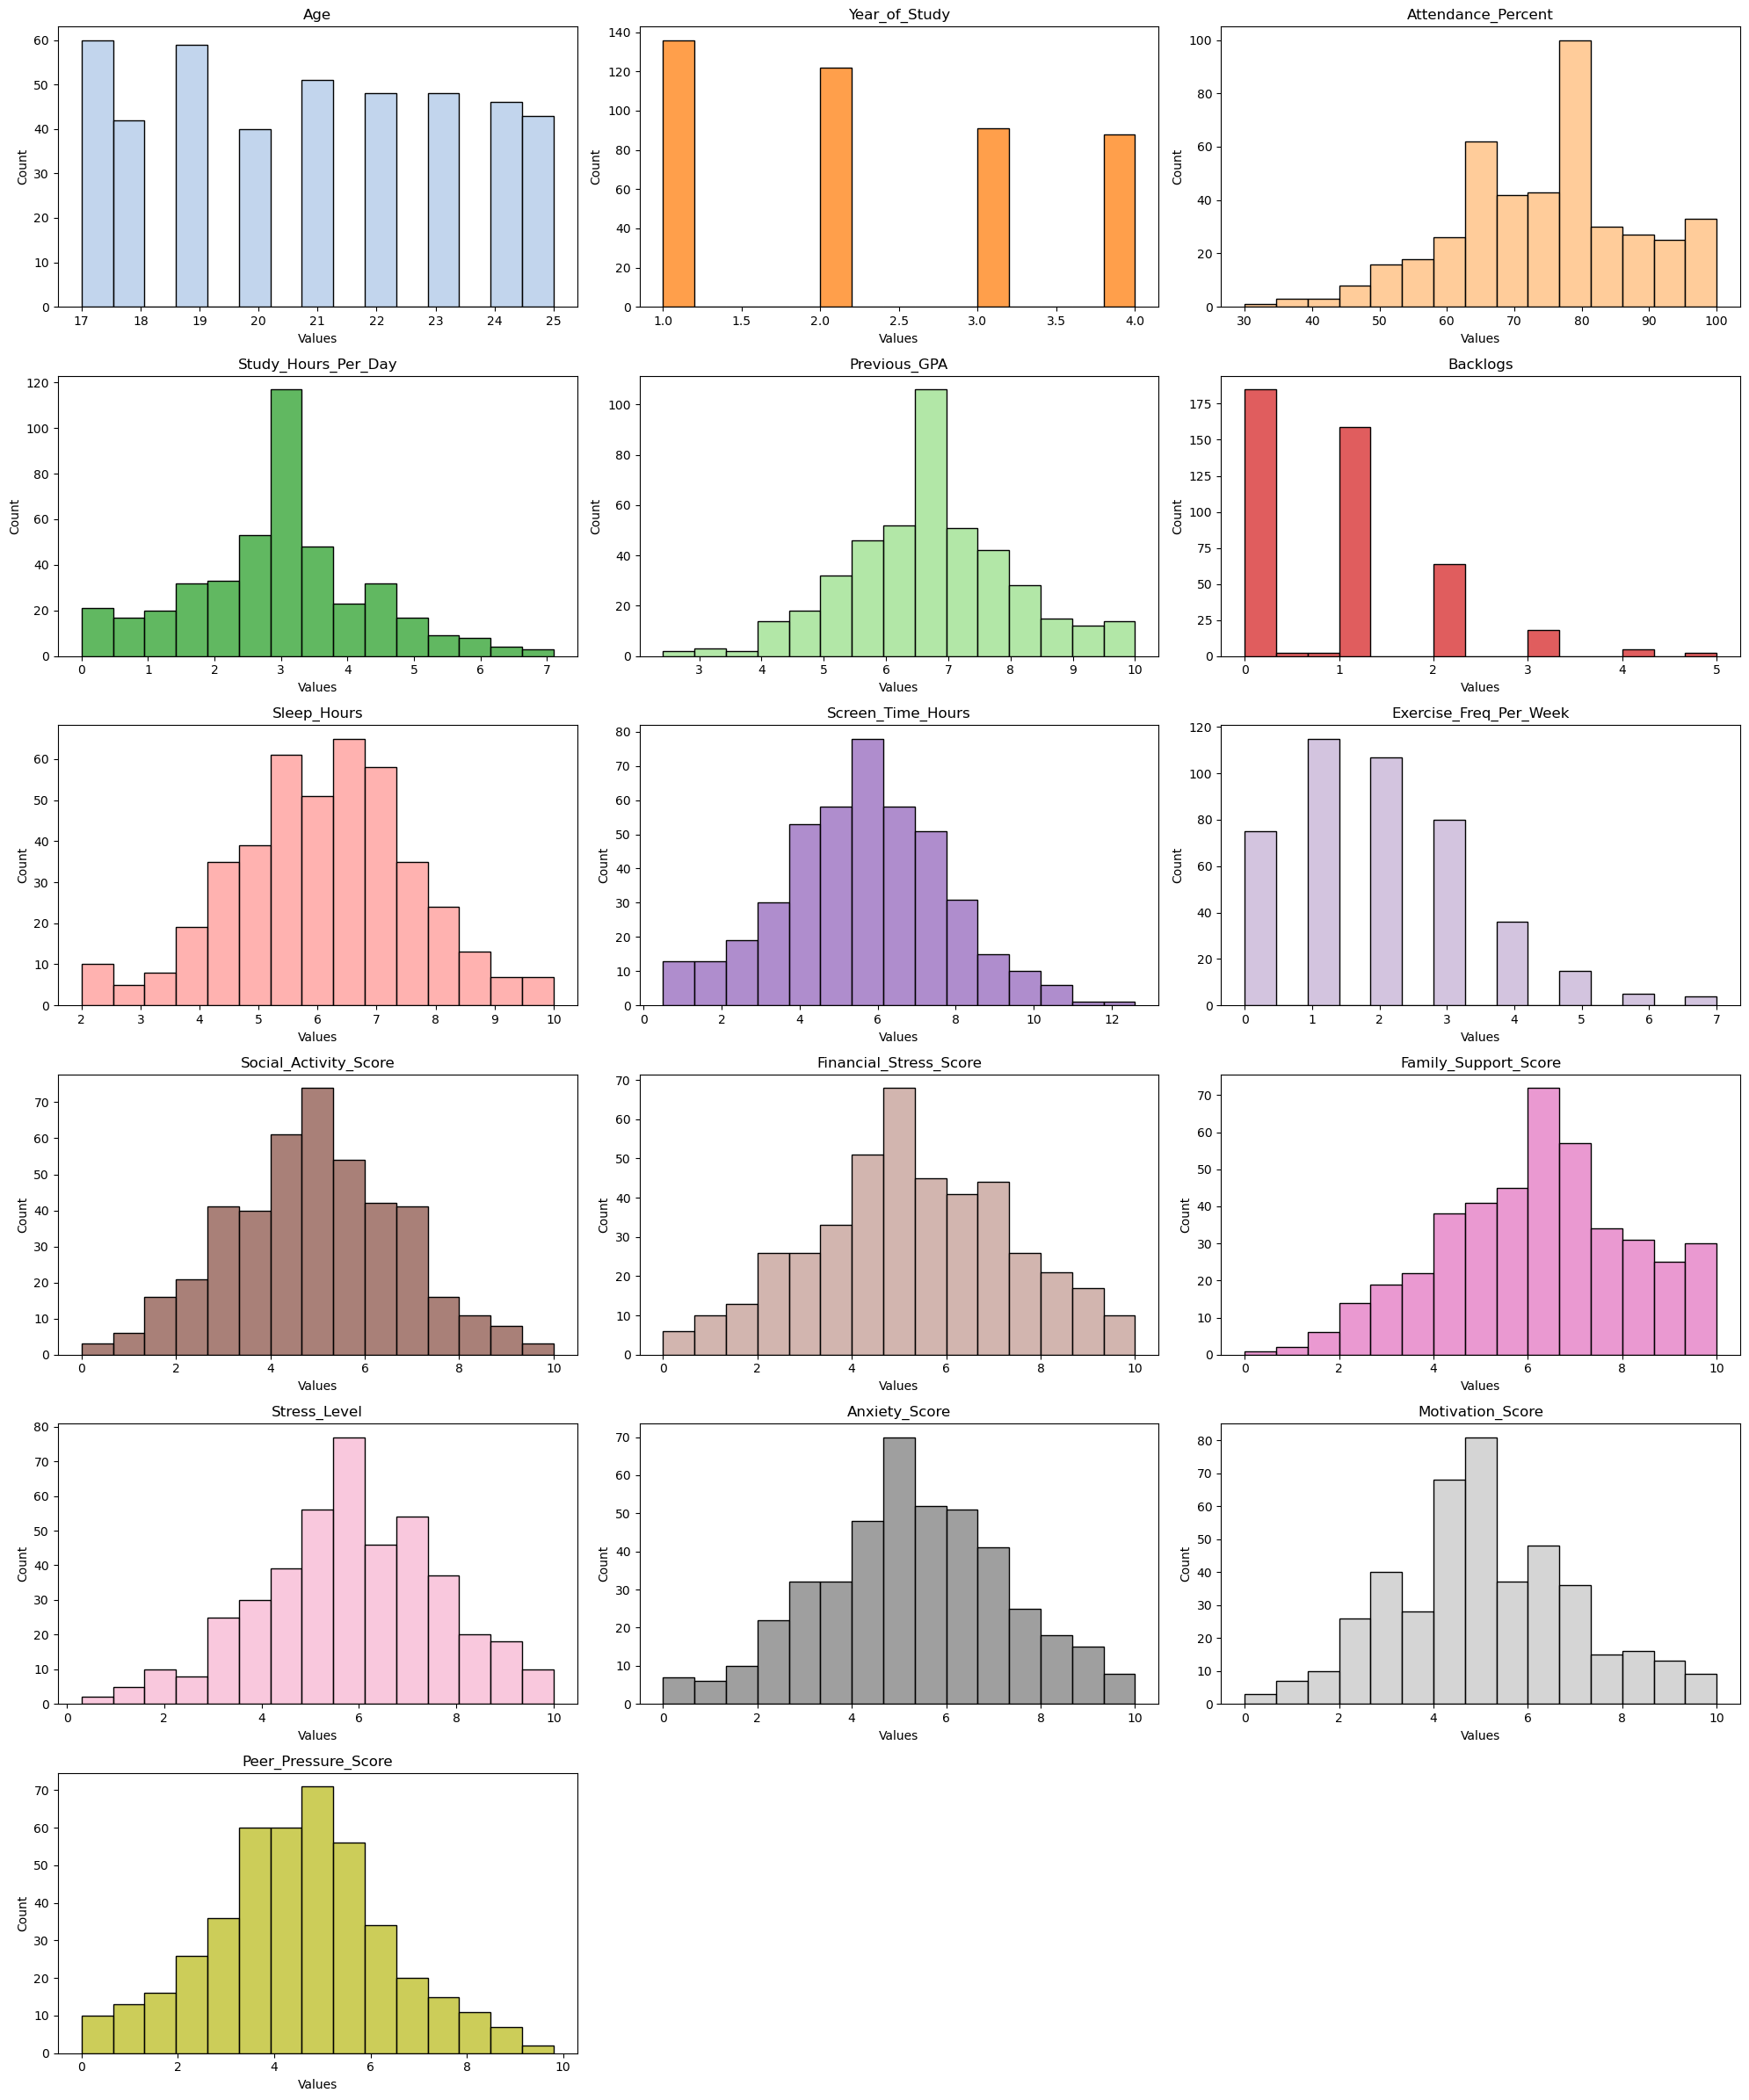

In [14]:
df_yes = df[df['Dropout_Risk'] == 'Yes'].copy()

numeric_cols = df_yes.select_dtypes(include=['int64','float64']).columns.tolist()

num_cols = numeric_cols
n = len(num_cols)

rows = math.ceil(n / 3)
cols = 3

plt.figure(figsize=(20, rows * 4))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(df_yes[col], bins=15, kde=False, color=sns.color_palette("tab20")[i % 20])
    plt.title(col)
    plt.xlabel("Values")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()